# Credit Card Fraud Detection — Fast Sparkov Version



In [ ]:
# 1. Imports and settings
import os, warnings, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve
)

RANDOM_STATE = 42
DATA_DIR = "/content/drive/MyDrive/CreditCardFraudDetection"
TRAIN_PATH = os.path.join(DATA_DIR, "fraudTrain.csv")
TEST_PATH = os.path.join(DATA_DIR, "fraudTest.csv")
TARGET = "is_fraud"

# Increase these only after the smaller version runs successfully.
MAX_TRAIN_ROWS = 50000
MAX_TEST_ROWS = 15000

drive.mount("/content/drive")
if not os.path.exists(TRAIN_PATH) or not os.path.exists(TEST_PATH):
    raise FileNotFoundError(
        f"CSV files not found. Check that these exist:\n{TRAIN_PATH}\n{TEST_PATH}"
    )
print("Files found. Ready to load data.")

Mounted at /content/drive
Files found. Ready to load data.


In [ ]:
# 2. Load data (only the columns needed)
# Keep the file loading straightforward, then sample rows to reduce training time.
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
print("Original train shape:", train_df.shape)
print("Original test shape:", test_df.shape)

if TARGET not in train_df.columns or TARGET not in test_df.columns:
    raise ValueError(f"Expected target column '{TARGET}' in both CSV files.")

def stratified_sample(df, n, target):
    if n is None or len(df) <= n:
        return df.copy()
    sampled, _ = train_test_split(
        df, train_size=n, stratify=df[target], random_state=RANDOM_STATE
    )
    return sampled.copy()

train_df = stratified_sample(train_df, MAX_TRAIN_ROWS, TARGET)
test_df = stratified_sample(test_df, MAX_TEST_ROWS, TARGET)
print("Sampled train shape:", train_df.shape)
print("Sampled test shape:", test_df.shape)
print("\nTraining fraud rate:", round(train_df[TARGET].mean(), 5))
print("Testing fraud rate:", round(test_df[TARGET].mean(), 5))

Original train shape: (1296675, 23)
Original test shape: (555719, 23)
Sampled train shape: (50000, 23)
Sampled test shape: (15000, 23)

Training fraud rate: 0.00578
Testing fraud rate: 0.00387


In [ ]:
# 3. Feature engineering: compact features only
def make_features(df):
    df = df.copy()
    if "trans_date_trans_time" in df.columns:
        dt = pd.to_datetime(df["trans_date_trans_time"], errors="coerce")
        df["trans_hour"] = dt.dt.hour
        df["trans_dayofweek"] = dt.dt.dayofweek
        df["trans_month"] = dt.dt.month

    if "dob" in df.columns and "trans_date_trans_time" in df.columns:
        dob = pd.to_datetime(df["dob"], errors="coerce")
        dt = pd.to_datetime(df["trans_date_trans_time"], errors="coerce")
        df["age"] = ((dt - dob).dt.days / 365.25).clip(0, 120)

    numeric_candidates = [
        "amt", "lat", "long", "city_pop", "merch_lat", "merch_long",
        "trans_hour", "trans_dayofweek", "trans_month", "age"
    ]
    categorical_candidates = ["category", "gender", "state"]
    numeric_cols = [c for c in numeric_candidates if c in df.columns]
    categorical_cols = [c for c in categorical_candidates if c in df.columns]
    X = df[numeric_cols + categorical_cols].copy()

    for c in numeric_cols:
        X[c] = pd.to_numeric(X[c], errors="coerce")
    for c in categorical_cols:
        X[c] = X[c].fillna("Unknown").astype(str)
    return X, numeric_cols, categorical_cols

X_train, numeric_cols, categorical_cols = make_features(train_df)
X_test, _, _ = make_features(test_df)
X_test = X_test.reindex(columns=X_train.columns)
y_train = train_df[TARGET].astype(int)
y_test = test_df[TARGET].astype(int)

print("Numeric features:", numeric_cols)
print("Categorical features:", categorical_cols)
print("Feature shapes:", X_train.shape, X_test.shape)

Numeric features: ['amt', 'lat', 'long', 'city_pop', 'merch_lat', 'merch_long', 'trans_hour', 'trans_dayofweek', 'trans_month', 'age']
Categorical features: ['category', 'gender', 'state']
Feature shapes: (50000, 13) (15000, 13)


In [ ]:
# 4. Preprocessing and models
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

svm_model = Pipeline([
    ("prep", preprocessor),
    ("model", LinearSVC(class_weight="balanced", random_state=RANDOM_STATE, max_iter=2000))
])
rf_model = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=60, max_depth=18, min_samples_leaf=2,
        class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1
    ))
])
lr_model = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(
        class_weight="balanced", max_iter=300, solver="liblinear",
        random_state=RANDOM_STATE
    ))
])
voting_model = VotingClassifier(
    estimators=[("rf", rf_model), ("lr", lr_model)],
    voting="soft", weights=[2, 1], n_jobs=1
)
models = {
    "Linear SVM": svm_model,
    "Random Forest": rf_model,
    "Voting Classifier (RF + LR)": voting_model
}
print("Models prepared.")

Models prepared.


In [ ]:
# 5. Train, predict, and compare metrics
trained_models, predictions, scores, results = {}, {}, {}, []
for name, model in models.items():
    start = time.time()
    print(f"Training {name} ...", flush=True)
    model.fit(X_train, y_train)
    trained_models[name] = model
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    if name == "Linear SVM":
        y_score = model.decision_function(X_test)
    else:
        y_score = model.predict_proba(X_test)[:, 1]
    scores[name] = y_score

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score),
        "Average Precision": average_precision_score(y_test, y_score),
        "Time (sec)": round(time.time() - start, 1)
    })
    print(f"Finished {name} in {time.time() - start:.1f} seconds.", flush=True)

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))

Training Linear SVM ...
Finished Linear SVM in 1.5 seconds.
Training Random Forest ...
Finished Random Forest in 8.3 seconds.
Training Voting Classifier (RF + LR) ...
Finished Voting Classifier (RF + LR) in 8.9 seconds.


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision,Time (sec)
Model,,,,,,,
Linear SVM,0.9105,0.0279,0.6552,0.0536,0.8140,0.0987,1.5
Random Forest,0.9978,0.8049,0.5690,0.6667,0.9500,0.6683,8.3
Voting Classifier (RF + LR),0.9953,0.4286,0.6207,0.5070,0.9353,0.6005,8.9



Linear SVM
              precision    recall  f1-score   support

           0     0.9985    0.9115    0.9530     14942
           1     0.0279    0.6552    0.0536        58

    accuracy                         0.9105     15000
   macro avg     0.5132    0.7833    0.5033     15000
weighted avg     0.9948    0.9105    0.9496     15000

TN=13,620 | FP=1,322 | FN=20 | TP=38


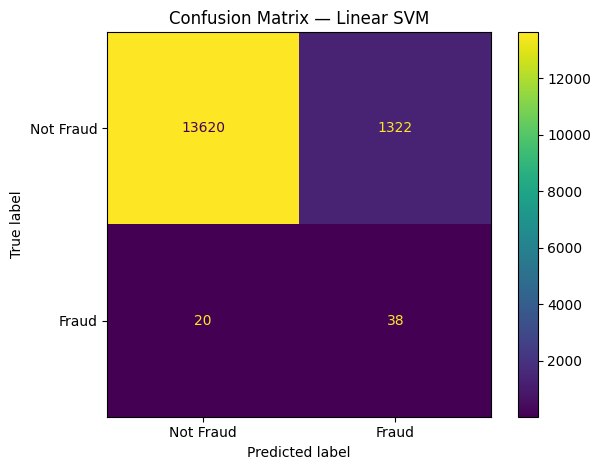


Random Forest
              precision    recall  f1-score   support

           0     0.9983    0.9995    0.9989     14942
           1     0.8049    0.5690    0.6667        58

    accuracy                         0.9978     15000
   macro avg     0.9016    0.7842    0.8328     15000
weighted avg     0.9976    0.9978    0.9976     15000

TN=14,934 | FP=8 | FN=25 | TP=33


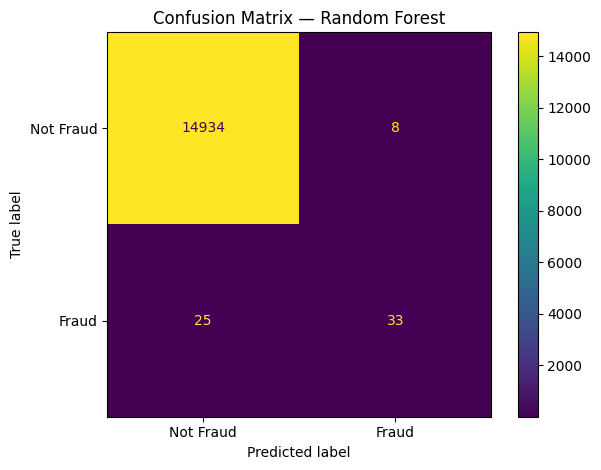


Voting Classifier (RF + LR)
              precision    recall  f1-score   support

           0     0.9985    0.9968    0.9977     14942
           1     0.4286    0.6207    0.5070        58

    accuracy                         0.9953     15000
   macro avg     0.7135    0.8087    0.7523     15000
weighted avg     0.9963    0.9953    0.9958     15000

TN=14,894 | FP=48 | FN=22 | TP=36


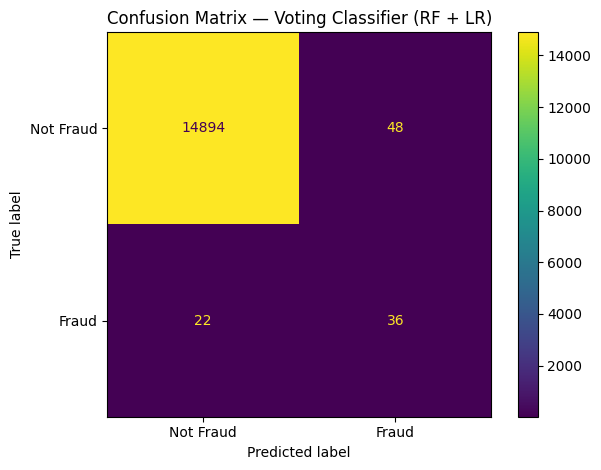

In [ ]:
# 6. Classification reports and confusion matrices
for name in trained_models:
    print("\n" + "=" * 55 + "\n" + name + "\n" + "=" * 55)
    print(classification_report(y_test, predictions[name], digits=4, zero_division=0))
    cm = confusion_matrix(y_test, predictions[name], labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    print(f"TN={tn:,} | FP={fp:,} | FN={fn:,} | TP={tp:,}")
    ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=["Not Fraud", "Fraud"]
    ).plot(values_format="d")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

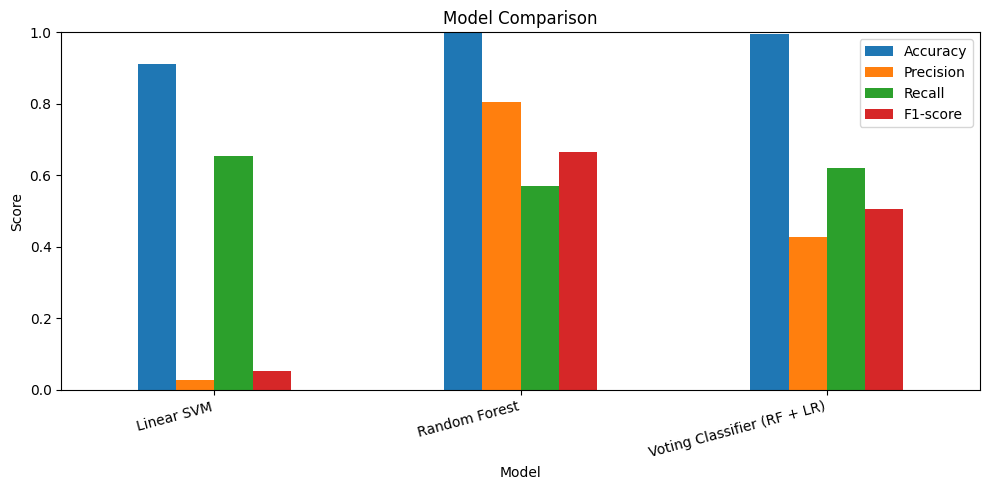

In [ ]:
# 7. Compare Accuracy, Precision, Recall, and F1-score
metric_cols = ["Accuracy", "Precision", "Recall", "F1-score"]
ax = results_df[metric_cols].plot(kind="bar", figsize=(10, 5), ylim=(0, 1))
ax.set_title("Model Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

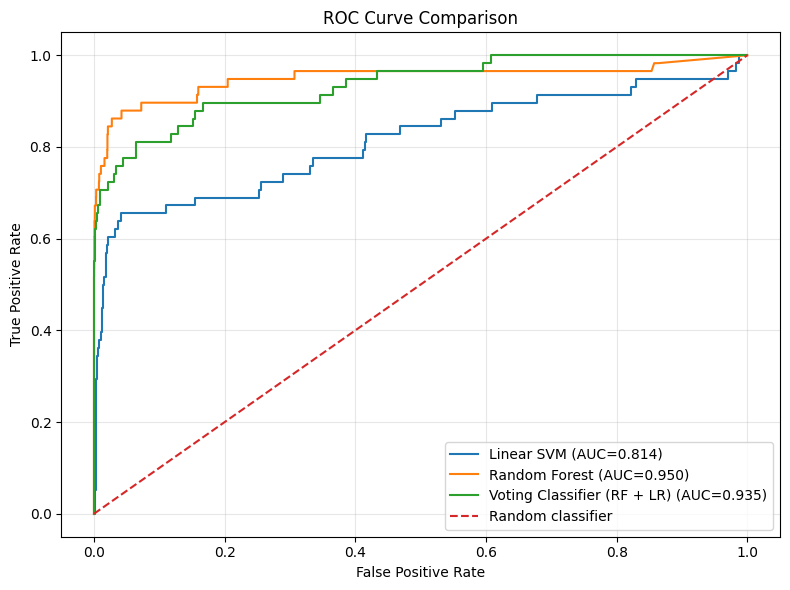

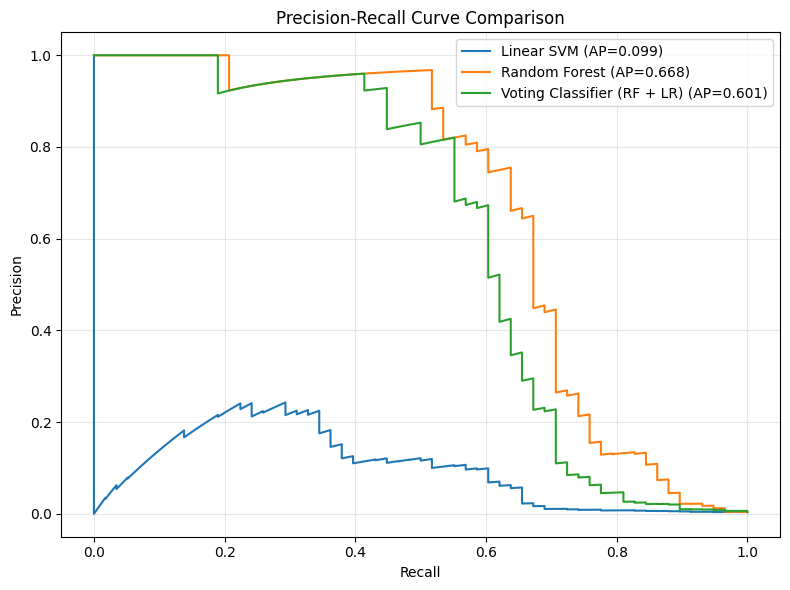

In [ ]:
# 8. ROC curves and Precision-Recall curves
plt.figure(figsize=(8, 6))
for name, y_score in scores.items():
    fpr, tpr, _ = roc_curve(y_test, y_score)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, y_score):.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
for name, y_score in scores.items():
    precision, recall, _ = precision_recall_curve(y_test, y_score)
    plt.plot(recall, precision, label=f"{name} (AP={average_precision_score(y_test, y_score):.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# 9. Save metrics and predictions to Google Drive
os.makedirs(DATA_DIR, exist_ok=True)
metrics_path = os.path.join(DATA_DIR, "model_comparison_metrics_fast.csv")
results_df.to_csv(metrics_path)

for name in trained_models:
    safe_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("+", "plus").replace("-", "_")
    pd.DataFrame({
        "actual_is_fraud": y_test.to_numpy(),
        "predicted_is_fraud": predictions[name],
        "fraud_score": scores[name]
    }).to_csv(os.path.join(DATA_DIR, f"{safe_name}_predictions_fast.csv"), index=False)

print("Saved metrics to:", metrics_path)
print("\nReminder: these results use stratified samples. Increase MAX_TRAIN_ROWS / MAX_TEST_ROWS for more representative evaluation if runtime allows.")

Saved metrics to: /content/drive/MyDrive/CreditCardFraudDetection/model_comparison_metrics_fast.csv

Reminder: these results use stratified samples. Increase MAX_TRAIN_ROWS / MAX_TEST_ROWS for more representative evaluation if runtime allows.
